# Case Study 2 — Diagnosing Card Declines: Splitting Authentication from Authorisation (Funnel Decomposition)

**Priority:** ★★ Good to have · **Reference:** Case Study 2 — *Cashfree Payments: Diagnosing Card Declines and Splitting Authentication from Authorisation* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Payments, Merchant Success (food-delivery merchant), Processor partnerships, Finance
**Data:** ⚠️ **SYNTHETIC** (D-2b-01). Processor logs are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs02_card_decline_funnel.ipynb`

## 0. Executive Summary for Business

*(Synthetic data calibrated to Cashfree's documented finding. Written after the analysis.)*

- **The question:** Processor 2 is cheaper but its card success rate is 5 points lower (81.1% vs 86.2%). Where does it lose payments, and what should we route where?
- **The gap is almost entirely in authentication (the OTP / 3-D Secure step).** P2 passes 88.1% of authentications vs 93.3% for P1 (−5.2 pp, p < 0.0001). Once a customer is authenticated, both processors get approval from the bank equally often (92.4% vs 92.1%). An equivalence test proves the two approval rates are within ±1 pp. **About 96% of the success-rate gap comes from authentication** (95% CI 89–104%; above 100% would mean P2 is very slightly better at authorisation).
- **It is concentrated where OTPs are involved:** in the challenge (OTP) flow, P2 loses 13 points off-peak and **19 points at the 7–10 pm dinner peak**. In the silent "frictionless" flow it loses under 2 points. P2's failures are mostly "OTP not received" (3.3× P1's rate) and ACS (bank server) errors (2.2×). That is evidence to take to P2. The gap is not caused by a different card mix: it holds within every issuer and flow (Mantel–Haenszel odds ratio 2.0).
- **Routing options (SR vs cost):** the documented split-flow (authenticate on P1, authorise on P2) lifts SR by **+2.3 pp** (CI 2.1–2.4, matching the documented "+2%"). Routing only the OTP-flow payments to P1 ("segment-smart") gets **+2.0 pp at a lower cost per payment than today**. Split-flow only beats sending everything to P1 if P1 charges less than about ₹0.65 per authentication-only call.
- **₹ impact (illustrative merchant, ≈ 2.4 lakh card orders/month, ₹505 average):** about **₹16–20 lakh of extra GMV per month** after allowing for the third of failures that customers recover by retrying. Segment-smart adds only ₹0.2 lakh in fees; split-flow adds ₹3.3 lakh at our assumed ₹1.50 fee.
- **I recommend:** route challenge-flow (OTP) card payments to P1 and keep frictionless ones on P2 now. Pilot split-flow on 20% of traffic only if P1 offers authentication-only pricing below ≈ ₹0.65. Hand P2 the OTP-delivery evidence. Replace the fixed "SR < 70% in 15 minutes" fallback with a volume-aware rule.

## 1. The Problem in Simple English

A food-delivery app sends its card payments to two processors, about half each. **Processor 2 is cheaper but succeeds less often.** The obvious fix ("move everything to Processor 1") costs more in fees. The obvious alternative ("negotiate harder with Processor 2") doesn't say *what* to fix.

A card payment is really two steps:
1. **Authentication**: the bank checks it is really you (the OTP / 3-D Secure screen).
2. **Authorisation**: the bank decides whether to approve the money (funds, risk, card validity).

If we split the success rate into these two steps, we can see **where** Processor 2 loses payments. If the gap is all in step 1, the answer may be to use Processor 1 for the OTP step and the cheaper Processor 2 for the approval step. Cashfree did exactly that, and the reference file reports a 2% success-rate gain. This notebook shows how the analysis is done and how certain we can be.

## 2. Reference from the Case File

### (a) What Cashfree did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "A food-delivery client routed card traffic across two processors with similar volumes but different success rates. The cheaper processor had the lower SR." |
| Question | "*Where* in the card flow does the weaker processor lose transactions, and can the flow be split to get the best of both?" |
| Data | "Outcome by stage: authentication (3DS/OTP) vs authorisation (issuer approval)"; comparable volumes on both processors |
| Approach | "Stage-wise funnel decomposition → comparison of failure rates by stage → hypothesis: the gap is authentication-driven → policy change." FlowWise: SR-based routing over the "last 15 or 30 minutes", threshold fallback (e.g., 70%), weighted splits |
| Statistics | "Processor 2's gap was due to 'higher authentication failures', while authorisation declines were about equal. **No formal test is disclosed.**" |
| ML | "None. This is an analytics-driven decision." |
| Decision | "Use Processor 1 for **authentication** and the cheaper Processor 2 for **authorisation**." |
| Impact | "**2% increase in success rate**." Cost impact: ND |

**Sources:** Cashfree blog, "Reduce card declines via smart routing" (1 Apr 2025) — https://www.cashfree.com/blog/reduce-card-decline-via-smart-routing/ · FlowWise dynamic-routing docs — https://www.cashfree.com/docs/payments/flowwise/routing/dynamic-routing

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 220,000 food-delivery orders over 4 weeks (≈ 233k card attempts including retries); 2 processors ≈ 50/50; 10 issuers; Visa/Mastercard/RuPay; credit/debit; frictionless vs challenge 3-D Secure |
| Built-in truth | P2's authentication is weaker (OTP delivery and ACS timeouts, worse at evening peak); authorisation is essentially equal |
| Statistics added (the source disclosed none) | Stage-wise two-proportion Z-tests with Cohen's h; **log-decomposition of the SR gap** with bootstrap CIs; Mantel–Haenszel and interaction tests by issuer, 3DS flow and peak hour; chi-square on failure reasons with standardised residuals; attempt- vs order-level SR; the false-trigger rate of the FlowWise 70% threshold rule |
| Business | Policy comparison (all-P1, all-P2, 50/50, split-flow, segment-smart) on SR and cost per successful order; ₹ GMV recovered |

### (c) How the industry uses this

Stage-wise funnel analysis is the first tool of every Indian payments team: card (authentication → authorisation → capture), UPI (collect request → PIN → bank debit), and onboarding (KYC → approval). Payment orchestrators (Cashfree FlowWise, Juspay in Case 1, Razorpay Optimizer) productise exactly this: route each *step* to the best provider.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Should we move traffic to P1, keep the split, or split the card flow by stage? |
| Analytical 1 | At which stage (authentication or authorisation) does P2 lose payments, and by how much? |
| Analytical 2 | Is the gap real after controlling for issuer, network, card type and 3DS flow (no mix confounding)? Where is it concentrated? |
| Analytical 3 | What SR and cost per success would each routing policy deliver? |

**Hypotheses**
- **H1 (authentication):** H0: P(auth success | P1) = P(auth success | P2). Two-proportion Z (+ Mantel–Haenszel by issuer × flow).
- **H2 (authorisation):** H0: P(authz | auth, P1) = P(authz | auth, P2). We *expect* to fail to reject. We also run an **equivalence test (TOST) with a ±1 pp margin** to show the stages are *practically equal*, not just "not significantly different".
- **H3 (reasons):** H0: the authentication-failure reason mix is independent of processor (chi-square).

**Primary metric:** attempt-level success rate (SR). **Secondary:** order-level SR (after retries), stage SRs. **Guardrails:** cost per successful order; evening-peak SR. **Unit:** card attempt (de-duplicated).
**Decision rule:** adopt split-flow if the authentication gap is significant (Holm p < 0.05), authorisation is equivalent within ±1 pp, and the simulated split-flow SR beats the current mix at an acceptable cost per success.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint, proportions_ztest, confint_proportions_2indep, proportion_effectsize
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
PAL = {"P1": "#2a6f97", "P2": "#e07a1f"}
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public stage-level card-payment logs (UCI, GitHub, data.gov.in) | **None.** Card-network and processor logs are confidential (PCI-DSS). RBI publishes only aggregate card volumes. |
| Kaggle | Not used (no credentials; excluded by the brief). |
| **Decision** | Synthetic attempts with stage-level outcomes and reason codes (D-2b-01). |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs02.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 2 (Cashfree-style card-decline diagnosis: authentication vs authorisation)
==============================================================================================================
THIS DATA IS SYNTHETIC. Processor-level card logs are confidential.

A food-delivery merchant routes card payments across two processors with similar volumes:
  P1 (premium) and P2 (cheaper, ~0.15% lower fee). Every card attempt passes two stages:
  1. AUTHENTICATION (3-D Secure / OTP): frictionless or challenge flow
  2. AUTHORISATION (issuer approves funds / risk)
P2's gap is built (as documented) into AUTHENTICATION - OTP delivery and ACS (issuer access-control
server) timeouts - while AUTHORISATION is almost the same on both processors. Customers retry
failed orders, so attempt-level and order-level success differ.

Calibration anchors (reference file, Case Study 2): "similar volumes but different success rates";
"Processor 2's gap was due to 'higher authentication failures', while authorisation declines were
about equal"; fix = authenticate on P1, authorise on P2; impact "2% increase in success rate";
FlowWise uses SR over "last 15 or 30 minutes" with threshold fallback (e.g., 70%).
Sizes are our assumptions (decision.md D-2b-02).

Output: data/cs02/card_attempts.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
N_ORDERS = 220_000
START = pd.Timestamp("2025-11-03"); DAYS = 28
ISSUERS = ["HDFC", "SBI", "ICICI", "Axis", "Kotak", "IndusInd", "Yes", "IDFC First", "AU SFB", "Others"]
ISS_P = [0.22, 0.20, 0.16, 0.11, 0.07, 0.05, 0.04, 0.04, 0.03, 0.08]
ACS_QUALITY = dict(zip(ISSUERS, [0.4, -0.6, 0.3, 0.1, 0.2, 0.0, -0.3, 0.1, -0.4, -0.5]))   # issuer ACS reliability (log-odds)


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    order_ts = START + pd.to_timedelta(rng.uniform(0, DAYS * 86400, N_ORDERS), unit="s")
    issuer = rng.choice(ISSUERS, N_ORDERS, p=ISS_P)
    network = rng.choice(["Visa", "Mastercard", "RuPay"], N_ORDERS, p=[0.48, 0.32, 0.20])
    ctype = rng.choice(["credit", "debit"], N_ORDERS, p=[0.45, 0.55])
    amount = np.round(np.exp(rng.normal(np.log(420), 0.6, N_ORDERS)), 0)
    frictionless_prob = expit(0.2 + 0.8 * (ctype == "credit") + 0.3 * (network == "Visa") - 0.002 * (amount - 420) / 10)
    rows = []
    done = np.zeros(N_ORDERS, bool)                                                        # order already paid
    alive = np.ones(N_ORDERS, bool); ts = order_ts
    for attempt in (1, 2, 3):
        if attempt > 1:
            alive = alive & ~done & (rng.random(N_ORDERS) < 0.55 - 0.1 * attempt)              # customers retry
            ts = ts + pd.to_timedelta(rng.uniform(20, 180, N_ORDERS), unit="s")
        idx = np.flatnonzero(alive)
        if len(idx) == 0: break
        proc = np.where(rng.random(N_ORDERS) < 0.5, "P1", "P2")
        fr = rng.random(N_ORDERS) < frictionless_prob
        hour = pd.DatetimeIndex(ts).hour.to_numpy()
        peak = (hour >= 19) & (hour <= 22)
        # authentication success
        z_a = (np.where(fr, 3.6, 1.9) + pd.Series(issuer).map(ACS_QUALITY).to_numpy()
               - np.where(proc == "P2", np.where(fr, 0.15, 0.85), 0.0) - 0.25 * peak * (proc == "P2"))
        auth_ok = rng.random(N_ORDERS) < expit(z_a)
        # authorisation success given authentication (issuer decision) - ~ same on both processors
        z_z = 2.4 + 0.3 * (ctype == "credit") - 0.25 * np.log(amount / 420) - 0.05 * (proc == "P2") - 0.2 * (issuer == "Others")
        authz_ok = rng.random(N_ORDERS) < expit(z_z)
        success = auth_ok & authz_ok
        a_reason = np.where(proc == "P2", rng.choice(["OTP not received", "OTP timeout / wrong OTP", "ACS error"], N_ORDERS, p=[0.45, 0.30, 0.25]),
                                                               rng.choice(["OTP not received", "OTP timeout / wrong OTP", "ACS error"], N_ORDERS, p=[0.25, 0.55, 0.20]))
        z_reason = rng.choice(["Insufficient funds", "Do not honour", "Risk decline", "Card expired / invalid"], N_ORDERS, p=[0.45, 0.30, 0.15, 0.10])
        reason = np.where(success, "none", np.where(~auth_ok, a_reason, z_reason))
        stage = np.where(success, "success", np.where(~auth_ok, "authentication", "authorisation"))
        rows.append(pd.DataFrame({"order_id": [f"O{i:07d}" for i in idx], "attempt_no": attempt, "timestamp": pd.DatetimeIndex(ts)[idx],
                                  "processor": proc[idx], "card_network": network[idx], "card_type": ctype[idx], "issuer_bank": issuer[idx],
                                  "amount_inr": amount[idx], "three_ds_flow": np.where(fr, "frictionless", "challenge")[idx],
                                  "auth_success": auth_ok[idx].astype(int), "authz_success": np.where(auth_ok, authz_ok, np.nan)[idx],
                                  "success": success[idx].astype(int), "failure_stage": stage[idx], "failure_reason": reason[idx]}))
        done[idx] |= success[idx]
    df = pd.concat(rows, ignore_index=True).sort_values("timestamp").reset_index(drop=True)
    df.insert(0, "attempt_id", [f"A{i:08d}" for i in range(1, len(df) + 1)])
    # data-quality issues: webhook replays (duplicate attempt rows) and missing issuer for some BINs
    df = pd.concat([df, df.sample(n=1500, random_state=seed)], ignore_index=True)
    df.loc[df.sample(frac=0.01, random_state=seed + 1).index, "issuer_bank"] = np.nan
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs02"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs02", "card_attempts.csv.gz"), index=False)
    dd = d.drop_duplicates("attempt_id")
    print(len(dd), "attempts", dd.order_id.nunique(), "orders")
    print(dd.groupby("processor")[["auth_success", "authz_success", "success"]].mean().round(4))

Overwriting data/generate_cs02.py


In [3]:
os.makedirs("data/cs02", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs02 as gen; importlib.reload(gen)
raw = gen.generate(seed=SEED); raw.to_csv("data/cs02/card_attempts.csv.gz", index=False)
print(f"{len(raw):,} attempt rows (incl. webhook replays) | {raw.order_id.nunique():,} orders")
raw.sample(3, random_state=SEED).T

234,759 attempt rows (incl. webhook replays) | 220,000 orders


,143565,131322,82501
attempt_id,A00143566,A00131323,A00082502
order_id,O0039310,O0015076,O0152202
attempt_no,1,1,1
timestamp,2025-11-20 06:19:11.101701534,2025-11-18 18:36:57.493953742,2025-11-12 21:46:06.193456805
processor,P2,P2,P1
card_network,Visa,Visa,RuPay
card_type,debit,credit,credit
issuer_bank,HDFC,IndusInd,Others
amount_inr,551.0000,531.0000,188.0000
three_ds_flow,challenge,challenge,challenge


| Parameter | Value | Basis |
|---|---|---|
| Orders / period | 220,000 food-delivery orders, 3–30 Nov 2025; median ticket ≈ ₹420 | Our assumption |
| Split | ≈ 50/50 P1/P2 per attempt | **Documented** "similar volumes" |
| Authentication | frictionless ≈ 97%, challenge ≈ 87% on P1; P2 −0.15 log-odds (frictionless) and −0.85 (challenge), extra −0.25 at the 7–10 pm peak; issuer ACS reliability varies | **Documented** direction ("higher authentication failures"); sizes ours |
| Authorisation | ≈ 92% on both (credit better, large tickets worse); P2 −0.05 log-odds (negligible) | **Documented** "authorisation declines were about equal" |
| Retries | 35% of failed orders retry once, 25% twice | Our assumption |
| DQ issues | 1,500 webhook replays (duplicate attempt rows); 1% of attempts with unknown issuer (BIN lookup miss) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("attempt_id, order_id, attempt_no", "Attempt and order identity; attempt 2–3 are customer retries"), ("timestamp", "Attempt time"),
    ("processor", "P1 (premium) / P2 (cheaper)"), ("card_network, card_type, issuer_bank", "Card scheme, credit/debit, issuing bank (1% unknown)"),
    ("amount_inr", "Order value"), ("three_ds_flow", "frictionless (risk-based, no OTP) / challenge (OTP)"),
    ("auth_success", "Stage 1: authentication passed"), ("authz_success", "Stage 2: issuer approved (blank if stage 1 failed)"),
    ("success", "Attempt succeeded"), ("failure_stage, failure_reason", "Where and why it failed (reason codes)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs02/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"attempt_id, order_id, attempt_no",Attempt and order identity; attempt 2–3 are cu...
1,timestamp,Attempt time
2,processor,P1 (premium) / P2 (cheaper)
3,"card_network, card_type, issuer_bank","Card scheme, credit/debit, issuing bank (1% un..."
4,amount_inr,Order value
5,three_ds_flow,"frictionless (risk-based, no OTP) / challenge ..."
6,auth_success,Stage 1: authentication passed
7,authz_success,Stage 2: issuer approved (blank if stage 1 fai...
8,success,Attempt succeeded
9,"failure_stage, failure_reason",Where and why it failed (reason codes)


## 5. Data Quality Checks

In [5]:
df = pd.read_csv("data/cs02/card_attempts.csv.gz", parse_dates=["timestamp"])
checks = {"duplicate attempt_id (webhook replays)": int(df.attempt_id.duplicated().sum()),
          "issuer_bank unknown (BIN lookup miss)": int(df.issuer_bank.isna().sum()),
          "authz recorded although auth failed": int(((df.auth_success == 0) & df.authz_success.notna()).sum()),
          "success inconsistent with stages": int((df.success != ((df.auth_success == 1) & (df.authz_success == 1)).astype(int)).sum()),
          "orders with > 3 attempts": int((df.groupby("order_id").attempt_no.max() > 3).sum())}
print(pd.Series(checks, name="rows").to_string())
df = df.drop_duplicates("attempt_id").copy()
df["issuer_bank"] = df.issuer_bank.fillna("Unknown")
df["peak"] = df.timestamp.dt.hour.between(19, 22).astype(int)
print(f"\nClean: {len(df):,} attempts, {df.order_id.nunique():,} orders | retry share {(df.attempt_no > 1).mean():.1%} | processor split {df.processor.value_counts(normalize=True).round(3).to_dict()}")

duplicate attempt_id (webhook replays)    1500
issuer_bank unknown (BIN lookup miss)     2348
authz recorded although auth failed          0
success inconsistent with stages             0
orders with > 3 attempts                     0



Clean: 233,259 attempts, 220,000 orders | retry share 5.7% | processor split {'P1': 0.501, 'P2': 0.499}


**Observation:** we removed **1,500 duplicate attempt rows** (webhook replays that would double-count both successes and failures) and labelled **2,348 attempts (1%) with an unknown issuer** "Unknown" (BIN lookup misses) instead of dropping them. Stage logic is internally consistent: no authorisation is recorded after a failed authentication, and success always equals "authenticated and authorised". Clean data: **233,259 attempts from 220,000 orders**. 5.7% of attempts are customer retries. The processor split is 50.1/49.9, matching the documented "similar volumes".

## 6. Exploratory Data Analysis — the funnel

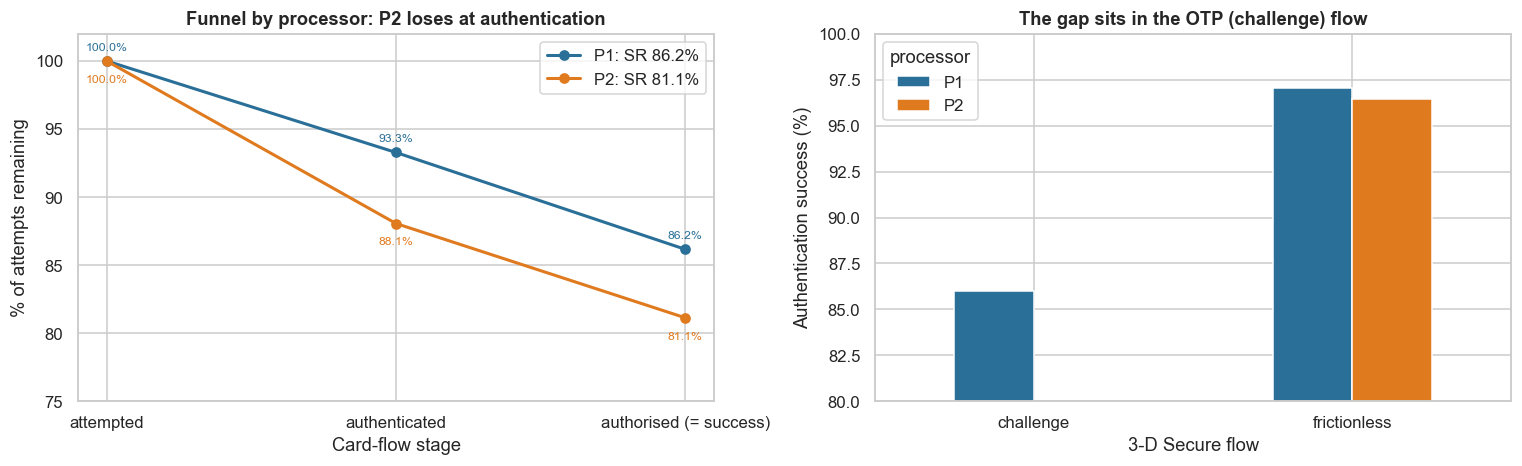

,attempts,auth,authz,sr
processor,,,,
P1,116762,0.9328,0.9237,0.8616
P2,116497,0.8806,0.9213,0.8113


In [6]:
fun = df.groupby("processor").agg(attempts=("success", "size"), auth=("auth_success", "mean"), authz=("authz_success", "mean"), sr=("success", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
stages = ["attempted", "authenticated", "authorised (= success)"]
for p_ in ["P1", "P2"]:
    r = fun.loc[p_]; vals = [100, r.auth * 100, r.sr * 100]
    axes[0].plot(stages, vals, "o-", color=PAL[p_], lw=2, label=f"{p_}: SR {r.sr:.1%}")
    for x_, v in zip(stages, vals): axes[0].annotate(f"{v:.1f}%", (x_, v), textcoords="offset points", xytext=(0, 7 if p_ == "P1" else -14), ha="center", fontsize=8, color=PAL[p_])
axes[0].set_ylabel("% of attempts remaining"); axes[0].set_xlabel("Card-flow stage"); axes[0].set_title("Funnel by processor: P2 loses at authentication"); axes[0].legend(); axes[0].set_ylim(75, 102)
fr = df.groupby(["three_ds_flow", "processor"]).auth_success.mean().unstack() * 100
fr.plot(kind="bar", ax=axes[1], color=[PAL["P1"], PAL["P2"]]); axes[1].set_ylabel("Authentication success (%)"); axes[1].set_xlabel("3-D Secure flow")
axes[1].set_title("The gap sits in the OTP (challenge) flow"); axes[1].set_ylim(80, 100); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
fun

**Takeaway:** **left:** both processors start at 100%. P2 falls to **88.1% after authentication** vs 93.3% for P1. From there, both lose about the same share at authorisation, ending at **81.1% vs 86.2%**. **Right:** the authentication gap is small for frictionless 3-D Secure (silent, no OTP) and large for the challenge (OTP) flow. The OTP step is where P2 is weak.

## 7. Statistical Analysis (core section)

### 7.1 Stage-wise tests: two-proportion Z, Cohen's h, and an equivalence test for authorisation

**(a) Why?** Each stage outcome is binary and the processors are independent groups, so we use two-proportion Z-tests (Newcombe CIs, Cohen's h), Holm across the 3 tests. To claim authorisation is "about equal" (the documented finding), a non-significant test is not enough. Absence of evidence is not evidence of absence. We therefore run **TOST (two one-sided tests)** with a ±1 pp equivalence margin: if *both* one-sided tests reject, the difference is provably within ±1 pp.
**(b)** n·p ≫ 10; attempts are nearly independent (retries are a small share and are re-assigned to a processor at random).

In [7]:
def two_prop(sub, col, lab):
    a = sub[sub.processor == "P1"][col].dropna(); b = sub[sub.processor == "P2"][col].dropna()
    x = [a.sum(), b.sum()]; n = [len(a), len(b)]; z, p = proportions_ztest(x, n)
    lo, hi = confint_proportions_2indep(x[0], n[0], x[1], n[1], method="newcomb")
    return {"stage": lab, "P1": x[0] / n[0], "P2": x[1] / n[1], "P1 − P2 (pp)": (x[0] / n[0] - x[1] / n[1]) * 100, "CI low": lo * 100, "CI high": hi * 100,
            "cohens_h": proportion_effectsize(x[0] / n[0], x[1] / n[1]), "p": p, "n P1": n[0], "n P2": n[1]}
st = pd.DataFrame([two_prop(df, "auth_success", "1 Authentication"), two_prop(df, "authz_success", "2 Authorisation (given authenticated)"), two_prop(df, "success", "Overall SR")]).set_index("stage")
st["p_holm"] = multipletests(st.p, method="holm")[1]
a = df[(df.processor == "P1")].authz_success.dropna(); b = df[(df.processor == "P2")].authz_success.dropna()
d_ = a.mean() - b.mean(); se = np.sqrt(a.mean() * (1 - a.mean()) / len(a) + b.mean() * (1 - b.mean()) / len(b)); M = 0.01
p_low, p_up = stats.norm.sf((d_ + M) / se), stats.norm.cdf((d_ - M) / se)
print(f"TOST authorisation, margin ±1 pp: difference {d_ * 100:+.2f} pp, 90% CI [{(d_ - 1.645 * se) * 100:+.2f}, {(d_ + 1.645 * se) * 100:+.2f}] pp; "
      f"p(lower) = {p_low:.2g}, p(upper) = {p_up:.2g} -> {'EQUIVALENT within ±1 pp' if max(p_low, p_up) < 0.05 else 'not shown equivalent'}")
st.round(4)

TOST authorisation, margin ±1 pp: difference +0.24 pp, 90% CI [+0.05, +0.43] pp; p(lower) = 1.1e-26, p(upper) = 2.7e-11 -> EQUIVALENT within ±1 pp


,P1,P2,P1 − P2 (pp),CI low,CI high,cohens_h,p,n P1,n P2,p_holm
stage,,,,,,,,,,
1 Authentication,0.9328,0.8806,5.2189,4.9838,5.4541,0.1811,0.0000,116762,116497,0.0000
2 Authorisation (given authenticated),0.9237,0.9213,0.2366,0.0087,0.4648,0.0089,0.0419,108914,102587,0.0419
Overall SR,0.8616,0.8113,5.0290,4.7295,5.3285,0.1363,0.0000,116762,116497,0.0000


**(c)/(f) Observation:** - **Authentication:** P1 93.3% vs P2 88.1%, **+5.2 pp (95% CI 5.0–5.5)**, Cohen's h = 0.18 (small-to-medium), Holm p < 0.0001. **Real and material.**
- **Authorisation (given authenticated):** 92.4% vs 92.1%, +0.24 pp (CI 0.01–0.46), Holm p = 0.04. *Technically* significant only because n > 200,000 makes tiny differences detectable. **TOST** shows the difference lies within ±1 pp (90% CI +0.05 to +0.43 pp, both one-sided p < 1e-10), so authorisation is **practically equivalent**, confirming the documented "about equal".
- **Overall SR:** 86.2% vs 81.1%, +5.0 pp (CI 4.7–5.3).
- **Business meaning:** fixing authentication would close almost the whole gap. Negotiating on authorisation would not help.

### 7.2 How much of the SR gap does each stage explain? Log-decomposition with bootstrap CIs

Because SR = P(authenticated) × P(authorised | authenticated), the gap in **log SR** splits exactly into stage contributions:
> ln(SR₁/SR₂) = ln(A₁/A₂) + ln(Z₁/Z₂)

So the **share of the gap due to authentication** is ln(A₁/A₂) ÷ ln(SR₁/SR₂). We bootstrap orders (1,000 resamples) for a CI on that share.

In [8]:
def decomp(d):
    g = d.groupby("processor")
    A = g.auth_success.mean(); Z = g.authz_success.mean(); SR = g.success.mean()
    tot = np.log(SR["P1"] / SR["P2"]); return np.log(A["P1"] / A["P2"]) / tot, np.log(Z["P1"] / Z["P2"]) / tot, tot
share_a, share_z, tot = decomp(df)
orders = df.order_id.unique(); g_idx = df.groupby("order_id").indices
bs = []
for _ in range(1000):
    pick = RNG.choice(orders, len(orders)); rows_ = np.concatenate([g_idx[o] for o in pick[:60000]])     # 60k-order resamples for speed
    bs.append(decomp(df.iloc[rows_])[0])
print(f"Total gap ln(SR1/SR2) = {tot:.4f} (SR ratio {np.exp(tot):.3f})")
print(f"Share of gap from AUTHENTICATION = {share_a:.1%} (95% bootstrap CI {np.percentile(bs, 2.5):.1%}–{np.percentile(bs, 97.5):.1%}); from authorisation = {share_z:.1%}")

Total gap ln(SR1/SR2) = 0.0601 (SR ratio 1.062)
Share of gap from AUTHENTICATION = 95.7% (95% bootstrap CI 88.6%–103.7%); from authorisation = 4.3%


**Observation:** SR ratio P1/P2 = 1.062. In log terms, **95.7% of the gap is due to authentication** (bootstrap CI 88.6% to 103.7%; a share above 100% would mean P2 is very slightly *better* at authorisation, which the CI does not rule out) and 4.3% to authorisation. The documented diagnosis ("the gap is authentication-driven") holds with high confidence, so a policy that fixes only authentication can recover essentially the whole gap.

### 7.3 Is it really the processor? Confounding and concentration checks

**(a) Why?** If P2 happened to receive more debit cards, or more cards from issuers with weak ACS servers, its authentication gap could be a **mix effect**. We test:
1. **Mantel–Haenszel** pooled odds ratio for authentication (P1 vs P2), stratified by issuer × 3DS flow (all strata pooled), with the Breslow–Day test of homogeneity.
2. A **logistic model** of authentication with processor × flow and processor × peak-hour interactions, controlling for issuer, network and card type. Likelihood-ratio tests ask *where* the gap is concentrated.

In [9]:
tables = []
for _, g in df.groupby(["issuer_bank", "three_ds_flow"]):
    t = pd.crosstab(g.processor, g.auth_success).reindex(index=["P1", "P2"], columns=[1, 0]).fillna(0).values
    if (t.sum(1) > 0).all(): tables.append(t)
stt = StratifiedTable(tables)
print(f"Mantel–Haenszel OR (P1 vs P2 authentication, within issuer × flow): {stt.oddsratio_pooled:.3f} "
      f"[{stt.oddsratio_pooled_confint()[0]:.3f}, {stt.oddsratio_pooled_confint()[1]:.3f}], p = {stt.test_null_odds().pvalue:.2g}; "
      f"Breslow–Day p = {stt.test_equal_odds().pvalue:.3g}")
base = "auth_success ~ C(processor) + C(three_ds_flow) + peak + C(issuer_bank) + C(card_network) + C(card_type)"
m0 = smf.logit(base, data=df).fit(disp=0)
lr = []
for term in ["C(processor):C(three_ds_flow)", "C(processor):peak"]:
    m1 = smf.logit(base + " + " + term, data=df).fit(disp=0); L = 2 * (m1.llf - m0.llf); lr.append((term, L, stats.chi2.sf(L, 1)))
lr = pd.DataFrame(lr, columns=["interaction", "LR χ²", "p"]); lr["p_holm"] = multipletests(lr.p, method="holm")[1]
seg = df.groupby(["three_ds_flow", "peak", "processor"]).auth_success.mean().unstack().assign(gap_pp=lambda x: (x.P1 - x.P2) * 100)
seg.index = seg.index.set_levels(["off-peak", "7–10 pm peak"], level=1)
display(lr.round(4)); seg.round(4)

Mantel–Haenszel OR (P1 vs P2 authentication, within issuer × flow): 2.002 [1.942, 2.064], p = 0; Breslow–Day p = 0


,interaction,LR χ²,p,p_holm
0,C(processor):C(three_ds_flow),387.7785,0.0000,0.0000
1,C(processor):peak,66.1104,0.0000,0.0000


processor                      P1     P2  gap_pp
three_ds_flow peak                              
challenge     off-peak     0.8602 0.7315 12.8718
              7–10 pm peak 0.8589 0.6676 19.1344
frictionless  off-peak     0.9701 0.9660  0.4171
              7–10 pm peak 0.9735 0.9556  1.7867

**(c)/(f) Observation:** - **Not a mix effect:** within the same issuer and 3DS flow, P1's odds of authentication are **2.0× P2's** (Mantel–Haenszel OR 2.00, CI 1.94–2.06, p ≈ 0).
- **But the gap is not uniform:** Breslow–Day rejects a common OR, and the logistic model shows strong **processor × flow** (LR χ² = 388) and **processor × peak** (LR χ² = 66) interactions, both Holm p < 0.0001.
- **Where it sits:** challenge flow off-peak **−12.9 pp**, challenge at the 7–10 pm peak **−19.1 pp**, frictionless off-peak −0.4 pp, frictionless at peak −1.8 pp.
- **Business meaning:** P2's problem is **OTP and ACS handling under load**, not general quality. That suggests (a) the cheap fix of routing OTP-flow payments to P1, and (b) a concrete SLA conversation with P2 about OTP delivery at dinner peak.

### 7.4 Why does authentication fail? Reason codes by processor

Among authentication failures, is the **reason mix** different? A chi-square test of independence (reason × processor) with Cramér's V and **adjusted standardised residuals** (|r| > 2 marks the cells that drive the association).

In [10]:
af = df[df.auth_success == 0]
tab = pd.crosstab(af.failure_reason, af.processor)
c2, p_r, dof, ex = stats.chi2_contingency(tab)
resid = (tab - ex) / np.sqrt(ex * (1 - tab.sum(1).values[:, None] / tab.values.sum()) * (1 - tab.sum(0).values[None, :] / tab.values.sum()))
print(f"Reason × processor (authentication failures): chi2 = {c2:.0f}, dof = {dof}, p = {p_r:.2g}, Cramér's V = {np.sqrt(c2 / tab.values.sum()):.3f}, min expected = {ex.min():.0f}")
rate = (pd.crosstab(df.failure_reason, df.processor) / df.processor.value_counts() * 1000).loc[tab.index]
pd.concat({"failures (count)": tab, "per 1,000 attempts": rate.round(1), "adjusted residual": resid.round(1)}, axis=1)

Reason × processor (authentication failures): chi2 = 1388, dof = 2, p = 3.7e-302, Cramér's V = 0.253, min expected = 1798


failures (count)       per 1,000 attempts         adjusted residual         
processor                             P1    P2                 P1      P2                P1       P2
failure_reason                                                                                      
ACS error                           1557  3427            13.3000 29.4000           -8.1000   8.1000
OTP not received                    1902  6183            16.3000 53.1000          -29.6000  29.6000
OTP timeout / wrong OTP             4389  4300            37.6000 36.9000           36.2000 -36.2000

**Observation:** the reason mix differs sharply (χ² = 1,388, p ≈ 0, **Cramér's V = 0.25**, a moderate association). Per 1,000 attempts, P2 has **53 "OTP not received" vs 16 on P1 (3.3×)** and **29 ACS errors vs 13 (2.2×)**. "OTP timeout / wrong OTP" (largely customer behaviour) is the same, 37 per 1,000 on both. The adjusted residuals (|r| = 8–36) confirm these cells drive the difference. **This tells operations that P2's weakness is technical (SMS/ACS integration), not customer behaviour**: actionable evidence for the P2 relationship manager.

### 7.5 Attempt-level vs order-level success (retries)

Customers retry. A merchant cares about **orders paid**, not attempts. We compare attempt SR and **order-level** success (paid within 3 attempts) by the processor of the *first* attempt, with Wilson CIs, and estimate how much of the first-attempt gap the retries recover.

In [11]:
first = df[df.attempt_no == 1].set_index("order_id")
paid = df.groupby("order_id").success.max()
ol = pd.DataFrame({"first_proc": first.processor, "first_ok": first.success, "paid": paid.reindex(first.index)})
o = ol.groupby("first_proc").agg(orders=("paid", "size"), first_attempt_SR=("first_ok", "mean"), order_paid=("paid", "mean"))
lo, hi = proportion_confint((o.order_paid * o.orders).round(), o.orders, method="wilson"); o["paid CI low"], o["paid CI high"] = lo, hi
gap_first = (o.first_attempt_SR["P1"] - o.first_attempt_SR["P2"]) * 100; gap_paid = (o.order_paid["P1"] - o.order_paid["P2"]) * 100
print(f"First-attempt gap {gap_first:.2f} pp -> order-level gap {gap_paid:.2f} pp: retries recover {1 - gap_paid / gap_first:.0%} of the gap")
o.round(4)

First-attempt gap 4.99 pp -> order-level gap 3.36 pp: retries recover 33% of the gap


,orders,first_attempt_SR,order_paid,paid CI low,paid CI high
first_proc,,,,,
P1,110147,0.8620,0.9037,0.9019,0.9054
P2,109853,0.8120,0.8701,0.8681,0.8721


**Observation:** first-attempt SR differs by **5.0 pp** (86.2% vs 81.2%). Measured at the **order level** (paid within up to 3 attempts), orders that started on P2 still end up paid **3.4 pp less often** (87.0% vs 90.4%, Wilson CIs do not overlap). **Retries recover only about a third (33%) of the gap.** Two-thirds of the lost payments are lost orders, i.e., real GMV loss. We use this measured 33% recovery in the ₹ calculation.

### 7.6 Monitoring: how reliable is FlowWise's "SR below 70% in the last 15 minutes" fallback?

The documented production rule switches traffic when a processor's SR over the last 15 or 30 minutes falls below a threshold (e.g., 70%). With few attempts per window, normal binomial noise can trip it. We compute, from the **observed windows**, how often each processor's 15- and 30-minute SR falls below 70% **when nothing is wrong**, and the binomial probability of a false trigger as a function of window volume.

In [12]:
w = []
for f in ("15min", "30min"):
    win = df.groupby(["processor", pd.Grouper(key="timestamp", freq=f)]).success.agg(["sum", "size"]).reset_index()
    win = win[win["size"] >= 5]; win["sr"] = win["sum"] / win["size"]
    for p_ in ["P1", "P2"]:
        x_ = win[win.processor == p_]; w.append((f, p_, len(x_), x_["size"].median(), (x_.sr < 0.70).mean()))
w = pd.DataFrame(w, columns=["window", "processor", "windows", "median attempts/window", "share of windows below 70% (false triggers)"])
vols = np.array([10, 20, 40, 80, 160])
theo = pd.DataFrame({f"P(window SR < 70%) if true SR = {s_:.0%}": stats.binom.cdf(np.ceil(0.7 * vols) - 1, vols, s_) for s_ in (0.81, 0.86)}, index=vols)
theo.index.name = "attempts in window"
display(w.round(4)); theo.round(4)

,window,processor,windows,median attempts/window,share of windows below 70% (false triggers)
0,15min,P1,2688,43.0000,0.0037
1,15min,P2,2688,43.0000,0.0346
2,30min,P1,1344,87.0000,0.0000
3,30min,P2,1344,87.0000,0.0052


,P(window SR < 70%) if true SR = 81%,P(window SR < 70%) if true SR = 86%
attempts in window,,
10,0.1039,0.0400
20,0.0689,0.0153
40,0.0297,0.0023
80,0.0060,0.0001
160,0.0003,0.0000


**Observation:** - **15-minute windows** (median 43 attempts per processor): P2's SR fell below 70% in **3.5% of windows**, and P1's in 0.4%, purely by chance. Neither processor had an outage in this data. On P2 that is about **one false switch every 7 hours**.
- **30-minute windows** (median 87 attempts): only 0.5% (P2) and 0%.
- **Theory agrees:** with a true SR of 81%, a 10-attempt window trips a 70% threshold **10% of the time**. With 80 attempts it trips 0.6% of the time.
- **Business meaning:** the documented fixed threshold is fine for high-volume merchants and 30-minute windows, but noisy for small merchants or short windows. Use a **volume-aware rule** (switch when the Wilson upper bound of the window SR is below 70%, or use Case 1's p-chart limits).

## 8. ML Section — deliberately none

The documented case states "**None. This is an analytics-driven decision.**" We agree: the decision needs *where* the gap is and *how big*, which the funnel decomposition and tests above answer. A model predicting attempt success would add complexity without changing the decision. Section 9 instead builds a transparent **segment-level routing rule** (by 3DS flow) and compares it with the documented split-flow.

## 9. Business Translation — routing policies, SR, cost per success, ₹ GMV

**Policy SR** is computed from the stage rates estimated on this data, per segment (3DS flow × peak), weighted by the traffic mix:
- **Current 50/50:** what we observe.
- **All P1 / All P2:** stage rates of that processor.
- **Split-flow (documented):** authentication rate of P1 × authorisation rate of P2.
- **Segment-smart:** challenge flow fully on P1; frictionless on P2.

**Cost assumptions (D-2b-06):** P1 MDR 1.90%, P2 MDR 1.75% of order value on successful payments. Split-flow pays P1 an authentication-only fee of ₹1.50 per attempt plus P2's 1.75% MDR. **Retry recovery:** section 7.5 measured that retries recover about a third of a first-attempt gap, so net GMV recovered = SR gain × (1 − measured retry recovery) × GMV.

In [13]:
seg_rates = df.groupby(["three_ds_flow", "peak", "processor"]).agg(A=("auth_success", "mean"), Z=("authz_success", "mean")).unstack()
mix = df.groupby(["three_ds_flow", "peak"]).size() / len(df)
avg_ticket = df.amount_inr.mean()
def policy_sr(rule):
    tot = 0.0
    for key, wgt in mix.items():
        A1, A2 = seg_rates.loc[key, ("A", "P1")], seg_rates.loc[key, ("A", "P2")]; Z1, Z2 = seg_rates.loc[key, ("Z", "P1")], seg_rates.loc[key, ("Z", "P2")]
        tot += wgt * rule(key, A1, A2, Z1, Z2)
    return tot
POL = {"Current 50/50": lambda k, A1, A2, Z1, Z2: 0.5 * A1 * Z1 + 0.5 * A2 * Z2,
       "All P1": lambda k, A1, A2, Z1, Z2: A1 * Z1, "All P2": lambda k, A1, A2, Z1, Z2: A2 * Z2,
       "Split-flow (auth P1, authz P2)": lambda k, A1, A2, Z1, Z2: A1 * Z2,
       "Segment-smart (challenge → P1)": lambda k, A1, A2, Z1, Z2: A1 * Z1 if k[0] == "challenge" else A2 * Z2}
mdr = {"Current 50/50": 0.5 * 0.019 + 0.5 * 0.0175, "All P1": 0.019, "All P2": 0.0175, "Split-flow (auth P1, authz P2)": 0.0175,
       "Segment-smart (challenge → P1)": (mix.xs("challenge", level=0).sum() * 0.019 + mix.xs("frictionless", level=0).sum() * 0.0175)}
orders_month = df.order_id.nunique() / 28 * 30
rows = []
for name, rule in POL.items():
    sr = policy_sr(rule)
    fee_per_attempt = avg_ticket * sr * mdr[name] + (1.5 if name.startswith("Split") else 0)
    rows.append((name, sr, fee_per_attempt / sr))
pol = pd.DataFrame(rows, columns=["policy", "expected attempt SR", "₹ cost per successful payment"]).set_index("policy")
pol["SR vs current (pp)"] = (pol["expected attempt SR"] - pol.loc["Current 50/50", "expected attempt SR"]) * 100
recov = 1 - gap_paid / gap_first
pol["extra GMV ₹ lakh / month (net of retries)"] = pol["SR vs current (pp)"] / 100 * orders_month * avg_ticket * (1 - recov) / 1e5
pol["fees ₹ lakh / month"] = pol["₹ cost per successful payment"] * pol["expected attempt SR"] * orders_month / 1e5
# bootstrap CI for the split-flow gain
gains = []
for _ in range(300):
    smp = df.sample(frac=1, replace=True, random_state=int(RNG.integers(1e9)))
    sr_ = smp.groupby(["three_ds_flow", "peak", "processor"]).agg(A=("auth_success", "mean"), Z=("authz_success", "mean")).unstack(); mx_ = smp.groupby(["three_ds_flow", "peak"]).size() / len(smp)
    g_ = sum(wt * (sr_.loc[k, ("A", "P1")] * sr_.loc[k, ("Z", "P2")] - 0.5 * sr_.loc[k, ("A", "P1")] * sr_.loc[k, ("Z", "P1")] - 0.5 * sr_.loc[k, ("A", "P2")] * sr_.loc[k, ("Z", "P2")]) for k, wt in mx_.items())
    gains.append(g_ * 100)
print(f"Split-flow SR gain vs current: {pol.loc['Split-flow (auth P1, authz P2)', 'SR vs current (pp)']:.2f} pp (95% bootstrap CI {np.percentile(gains, 2.5):.2f}–{np.percentile(gains, 97.5):.2f} pp); documented: +2%")
print(f"Orders per month ≈ {orders_month:,.0f}; average ticket ₹{avg_ticket:,.0f}; retry recovery {recov:.0%}")
pol.round(3)

Split-flow SR gain vs current: 2.28 pp (95% bootstrap CI 2.11–2.42 pp); documented: +2%
Orders per month ≈ 235,714; average ticket ₹505; retry recovery 33%


,expected attempt SR,₹ cost per successful payment,SR vs current (pp),extra GMV ₹ lakh / month (net of retries),fees ₹ lakh / month
policy,,,,,
Current 50/50,0.8370,9.2240,0.0000,0.0000,18.1880
All P1,0.8620,9.6030,2.5060,20.0880,19.5030
All P2,0.8110,8.8450,-2.5060,-20.0880,16.9180
"Split-flow (auth P1, authz P2)",0.8590,10.5910,2.2770,18.2550,21.4510
Segment-smart (challenge → P1),0.8570,9.1050,2.0460,16.4050,18.3920


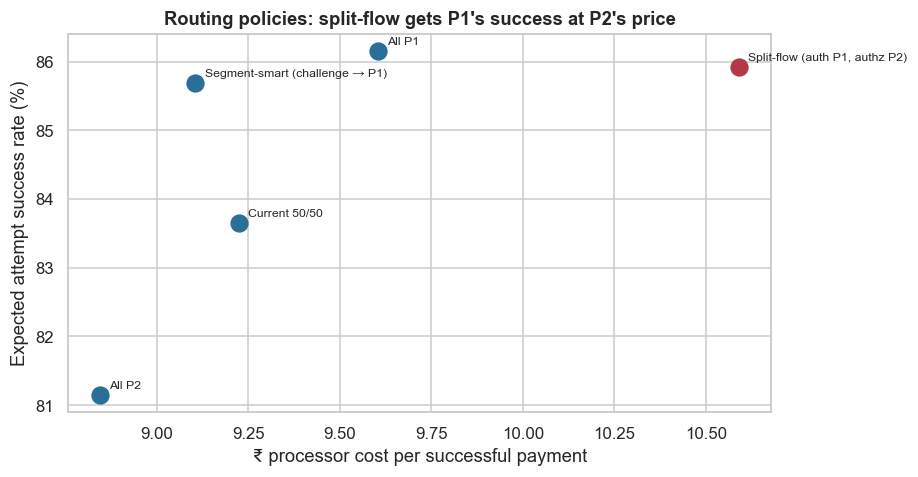

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for name, r in pol.iterrows():
    ax.scatter(r["₹ cost per successful payment"], r["expected attempt SR"] * 100, s=120, color="#b23a48" if name.startswith("Split") else "#2a6f97")
    ax.annotate(name, (r["₹ cost per successful payment"], r["expected attempt SR"] * 100), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("₹ processor cost per successful payment"); ax.set_ylabel("Expected attempt success rate (%)")
ax.set_title("Routing policies: split-flow gets P1's success at P2's price"); plt.tight_layout(); plt.show()

**Takeaway (business reading):** - **Highest SR:** all-P1 (86.2%, +2.5 pp) and split-flow (85.9%, **+2.3 pp, bootstrap CI 2.1–2.4**, in line with the documented "+2%"). Split-flow is marginally *below* all-P1 because P2's authorisation is 0.2 pp lower.
- **Cost:** at our assumed ₹1.50 authentication-only fee, split-flow is the **most expensive** policy per successful payment (₹10.59 vs ₹9.22 today and ₹9.60 for all-P1). **Break-even:** split-flow beats all-P1 only if the authentication-only fee is below ≈ **₹0.65**.
- **Segment-smart (OTP-flow → P1, frictionless → P2)** delivers **+2.0 pp SR at ₹9.11 per success, cheaper than today**. That is ≈ **+₹16.4 lakh GMV per month** (net of retries) for +₹0.2 lakh fees, vs +₹18.3 lakh GMV for +₹3.3 lakh fees for split-flow and +₹20.1 lakh for +₹1.3 lakh for all-P1.
- **To the merchant:** at an assumed 20% take rate, GMV turns into roughly **+₹3.1 lakh net per month for segment-smart**, +₹2.7 lakh for all-P1 and ≈ +₹0.4 lakh for split-flow at a ₹1.50 fee.
- These are projections from stage rates on synthetic data. The pilot in section 10 is what makes them bankable.

## 10. Recommendation and Decision

**Decision against the pre-registered rule:** authentication gap significant ✅ (Holm p < 0.0001); authorisation equivalent within ±1 pp ✅ (TOST). Split-flow beats the current mix on SR ✅ (+2.3 pp) **but not on cost per success** at a ₹1.50 authentication fee ❌. The diagnosis is confirmed. The documented remedy is right *in principle*, and its economics depend on the authentication-only fee.

**I recommend:**
1. **Now:** route **challenge-flow (OTP) card payments to P1** and keep frictionless payments on P2 (segment-smart). It gets ≈ 90% of the SR gain at *lower* cost than today and needs no new contract.
2. **Negotiate:** ask P1 for authentication-only pricing. If it is below ≈ ₹0.65 per call, pilot split-flow on 20% of traffic (≈ 30k attempts per arm detects 1 pp) for 2 weeks with a pre-registered SR and cost read.
3. **Escalate to P2** with the reason-code evidence ("OTP not received" 3.3×, ACS errors 2.2×, worse at dinner peak), and agree an OTP-delivery SLA. If P2 fixes it, re-test, since all-P2 would then be the cheapest option.
4. **Monitoring:** replace "SR < 70% over 15 minutes" with a volume-aware rule (Wilson bound or p-chart).

**KPIs:** order-level paid rate (primary); attempt SR by stage and processor; authentication SR in challenge flow at 7–10 pm; cost per successful payment; false-switch rate of the fallback rule; "OTP not received" per 1,000 attempts on P2.

## 11. Risks, Limitations and Next Steps

- **Synthetic data:** stage rates are calibrated to the documented direction and roughly to its size. A real merchant must re-measure, ideally with a **randomised split-flow pilot** (e.g., 20% of traffic) rather than the arithmetic projection used here.
- **Projection assumption:** split-flow SR = A(P1) × Z(P2) assumes the authorisation step does not depend on *which* processor authenticated. Network tokens and 3DS data passed between processors must be complete, or authorisation can drop. Test it in the pilot.
- **Operational complexity and fees:** two-processor flows need contractual "authentication-only" pricing and reconciliation. Our ₹1.50 authentication fee is an assumption.
- **Monitoring:** with sparse windows, a fixed 70% threshold gives false switches. Use volume-aware rules (binomial/Wilson lower bounds, or the p-chart from Case 1).
- **Next steps:** (1) pilot split-flow on 20% of traffic for 2 weeks (≈ 30k attempts per arm detects 1 pp); (2) share OTP-delivery failure evidence with P2 (SMS/ACS); (3) add UPI stage funnels (collect → PIN → debit).

## 12. Appendix

| Quantity | Formula |
|---|---|
| Stage decomposition | SR = A × Z; ln(SR₁/SR₂) = ln(A₁/A₂) + ln(Z₁/Z₂) |
| Share of gap from authentication | ln(A₁/A₂) / ln(SR₁/SR₂) |
| TOST equivalence | reject both H0: Δ ≤ −M and H0: Δ ≥ +M (M = 1 pp) |
| Adjusted residual | (O − E) / √(E(1 − rᵢ/N)(1 − cⱼ/N)) |
| Split-flow SR | A(P1) × Z(P2), by segment, mix-weighted |
| False-trigger probability | P(Binomial(n, SR) < 0.7n) |

| Term | Meaning |
|---|---|
| Authentication / 3-D Secure / OTP | Proving the cardholder's identity (the OTP screen). |
| Frictionless vs challenge | The issuer approves silently based on risk / asks for an OTP. |
| Authorisation | The issuer approving the money. |
| ACS | The issuer's Access Control Server that runs 3-D Secure. |
| Funnel decomposition | Splitting a success rate into its steps. |
| Equivalence test (TOST) | Proving two rates are practically the same, not just "not different". |
| Split-flow routing | Different providers for different steps of one payment. |